# Data Prepation 4: Preprocessing

In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import smogn
import numpy as np

### 1. Split data into train and test for RF
Columns like 'NORAD_CAT_ID', 'INTLDES', 'SATNAME' can be excluded from the model during the model creation process using ydf

In [44]:
# read data from csv
debris_df = pd.read_csv('../Data/Combined.csv')
debris_df.head()

,NORAD_CAT_ID,INTLDES,SATNAME,OBJECT_TYPE,COUNTRY,SITE,LAUNCH,DECAY,EPOCH,DAYS_SINCE_LAUNCH,...,INCLINATION,RA_OF_ASC_NODE,MEAN_ANOMALY,REV_AT_EPOCH,BSTAR,MEAN_MOTION_DOT,MEAN_MOTION_DDOT,SEMIMAJOR_AXIS,PERIOD,LIFETIME
0,23,1959-009B,JUNO II R/B,ROCKET BODY,US,AFETR,1959-10-13,1989-07-16,1982-01-13,8128,...,50.3043,233.6360,61.7000,16909.0,0.000982,0.000093,0.0,7012.727,97.406,10869
1,28,1960-002A,THOR ABLE R/B,ROCKET BODY,US,AFETR,1960-04-01,1991-07-03,1987-09-12,10025,...,48.3748,236.4746,264.6079,46764.0,0.000080,0.000006,0.0,6991.160,96.957,11415
2,30,1960-003A,THOR ABLESTAR R/B,ROCKET BODY,US,AFETR,1960-04-13,1961-08-18,1961-04-17,369,...,51.2500,272.4964,155.8967,5670.0,0.000000,0.001202,0.0,6750.239,91.989,492
3,35,1960-005B,SL-3 R/B,ROCKET BODY,CIS,TTMTR,1960-05-15,1960-07-17,1960-06-08,24,...,64.8899,183.4791,307.4432,380.0,0.000000,0.001764,0.0,6691.288,90.787,63
4,37,1960-005D,SPUTNIK 4 DEB,DEBRIS,CIS,TTMTR,1960-05-15,1961-06-30,1960-05-18,3,...,64.8899,254.4399,280.1511,63.0,0.000000,0.000000,0.0,6861.776,94.278,411


In [45]:
# split the data into training and test sets (80% training, 20% test)
train_df, test_df = train_test_split(debris_df, test_size=0.2, random_state=42)

print("Training set size:", len(train_df))
print("Test set size:", len(test_df))

Training set size: 19550
Test set size: 4888


In [46]:
# save to csv
train_df.to_csv("../Data/Train.csv", index=False)
test_df.to_csv("../Data/Test.csv", index=False)
debris_df.to_csv("../Data/DebrisRF.csv", index=False)

### 2. Preprocess data for the MLP

#### Handle DateTime colums

In [47]:
# read data from csv
debrisMLP_df = pd.read_csv('../Data/DebrisRF.csv')

# convert LAUNCH and EPOCH columns to datetime format
debrisMLP_df['LAUNCH'] = pd.to_datetime(debrisMLP_df['LAUNCH'])
debrisMLP_df['EPOCH'] = pd.to_datetime(debrisMLP_df['EPOCH'])

# extract year and month from Launch date and insert after Launch column
debrisMLP_df.insert(debrisMLP_df.columns.get_loc('LAUNCH') + 1, 'LAUNCH_YEAR', debrisMLP_df['LAUNCH'].dt.year)
debrisMLP_df.insert(debrisMLP_df.columns.get_loc('LAUNCH') + 2, 'LAUNCH_MONTH', debrisMLP_df['LAUNCH'].dt.month)

# extract year and month from Epoch date and insert after Epoch column
debrisMLP_df.insert(debrisMLP_df.columns.get_loc('EPOCH') + 1, 'EPOCH_YEAR', debrisMLP_df['EPOCH'].dt.year)
debrisMLP_df.insert(debrisMLP_df.columns.get_loc('EPOCH') + 2, 'EPOCH_MONTH', debrisMLP_df['EPOCH'].dt.month)

# drop original Launch and Epoch columns
debrisMLP_df.drop(columns=['LAUNCH', 'EPOCH'], inplace=True)

# save to csv
debrisMLP_df.to_csv("../Data/DebrisMLP.csv", index=False)

#### Train/Test split

In [48]:
debrisMLP_df.columns

Index(['NORAD_CAT_ID', 'INTLDES', 'SATNAME', 'OBJECT_TYPE', 'COUNTRY', 'SITE',
       'LAUNCH_YEAR', 'LAUNCH_MONTH', 'DECAY', 'EPOCH_YEAR', 'EPOCH_MONTH',
       'DAYS_SINCE_LAUNCH', 'REMAINING_LIFETIME', 'PERIAPSIS', 'APOAPSIS',
       'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION',
       'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR',
       'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD',
       'LIFETIME'],
      dtype='object')

In [49]:
# define feature and label columns
feature_columns = ['NORAD_CAT_ID', 'OBJECT_TYPE', 'COUNTRY', 'SITE', 'LAUNCH_YEAR', 'LAUNCH_MONTH', 'EPOCH_YEAR', 'EPOCH_MONTH', 'DAYS_SINCE_LAUNCH', 'PERIAPSIS', 'APOAPSIS', 'ARG_OF_PERICENTER', 'MEAN_MOTION', 'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE', 'MEAN_ANOMALY', 'REV_AT_EPOCH', 'BSTAR', 'MEAN_MOTION_DOT', 'MEAN_MOTION_DDOT', 'SEMIMAJOR_AXIS', 'PERIOD']
label_column1 = 'LIFETIME'
label_column2 = 'REMAINING_LIFETIME'

x = debrisMLP_df[feature_columns]
y1 = debrisMLP_df[label_column1]
y2 = debrisMLP_df[label_column2]

In [50]:
# split x and y data into train and test
# 80% training, 20% testing
x_train, x_test, y_train_lifetime, y_test_lifetime = train_test_split(x, y1, test_size=0.2, random_state=42)

# use the same indices for the remaining lifetime label
y_train_remaining = y2.loc[y_train_lifetime.index]
y_test_remaining = y2.loc[y_test_lifetime.index]

In [51]:
# show datatypes in x_train
print(x_train.dtypes)

NORAD_CAT_ID           int64
OBJECT_TYPE           object
COUNTRY               object
SITE                  object
LAUNCH_YEAR            int32
LAUNCH_MONTH           int32
EPOCH_YEAR             int32
EPOCH_MONTH            int32
DAYS_SINCE_LAUNCH      int64
PERIAPSIS            float64
APOAPSIS             float64
ARG_OF_PERICENTER    float64
MEAN_MOTION          float64
ECCENTRICITY         float64
INCLINATION          float64
RA_OF_ASC_NODE       float64
MEAN_ANOMALY         float64
REV_AT_EPOCH         float64
BSTAR                float64
MEAN_MOTION_DOT      float64
MEAN_MOTION_DDOT     float64
SEMIMAJOR_AXIS       float64
PERIOD               float64
dtype: object


#### One Hot Encoding of categorical features

In [52]:
# encode non numerical columns using One Hot Encoding 
from sklearn.preprocessing import OneHotEncoder

categorical_cols = x_train.select_dtypes(include=["object"]).columns.tolist()

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
x_train_encoded = encoder.fit_transform(x_train[categorical_cols]) # only fit the encoder to training dataset to avoid data leakage
x_test_encoded = encoder.transform(x_test[categorical_cols])

# convert to dataframes
encoded_cols = encoder.get_feature_names_out(categorical_cols)
x_train_encoded = pd.DataFrame(x_train_encoded, columns=encoded_cols, index=x_train.index)
x_test_encoded = pd.DataFrame(x_test_encoded, columns=encoded_cols, index=x_test.index)

# print columns 
print("Encoded categorical columns:")
for col in categorical_cols:
    print(f"- {col}")

Encoded categorical columns:
- OBJECT_TYPE
- COUNTRY
- SITE


#### Normalizing numerical features using standardization

In [53]:
from sklearn.preprocessing import StandardScaler # (z-Normalisierung)
import numpy as np

# get only numeric columns
numeric_cols = x_train.select_dtypes(include=[np.number]).columns.drop('NORAD_CAT_ID').tolist()

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train[numeric_cols]) # only fit scaler on training set to avoid data leakage
x_test_scaled = scaler.transform(x_test[numeric_cols])

# convert to dataframes
x_train_scaled = pd.DataFrame(x_train_scaled, columns=numeric_cols, index=x_train.index)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=numeric_cols, index=x_test.index)

# print columns
print("Scaled numeric columns:")
for col in numeric_cols:
    print(f"- {col}")

Scaled numeric columns:
- LAUNCH_YEAR
- LAUNCH_MONTH
- EPOCH_YEAR
- EPOCH_MONTH
- DAYS_SINCE_LAUNCH
- PERIAPSIS
- APOAPSIS
- ARG_OF_PERICENTER
- MEAN_MOTION
- ECCENTRICITY
- INCLINATION
- RA_OF_ASC_NODE
- MEAN_ANOMALY
- REV_AT_EPOCH
- BSTAR
- MEAN_MOTION_DOT
- MEAN_MOTION_DDOT
- SEMIMAJOR_AXIS
- PERIOD


In [54]:
# combinde encoded and normalized features (and ID)
x_train_final = pd.concat([x_train['NORAD_CAT_ID'], x_train_encoded, x_train_scaled], axis=1)
x_test_final = pd.concat([x_test['NORAD_CAT_ID'], x_test_encoded, x_test_scaled], axis=1)

In [55]:
# combine with label columns
x_train_final["LIFETIME"] = y_train_lifetime
x_test_final["LIFETIME"] = y_test_lifetime

x_train_final["REMAINING_LIFETIME"] = y_train_remaining
x_test_final["REMAINING_LIFETIME"] = y_test_remaining

In [56]:
# save to csv
x_train_final.to_csv("../Data/TrainPreprocessed.csv", index=False)
x_test_final.to_csv("../Data/TestPreprocessed.csv", index=False)

## 3. Balancing the dataset
Using Remaining Lifetime as the label and the one hot encoded + normalized features as the input

### Oversampling using SMOTE technique for regression with Gaussian Noise using [smogn](https://pypi.org/project/smogn/) library

In [8]:
# read data from csv
x_train_final = pd.read_csv('../Data/TrainPreprocessed.csv')
x_test_final = pd.read_csv('../Data/TestPreprocessed.csv')
debrisMLP_df = pd.read_csv('../Data/DebrisMLP.csv')

In [ ]:
# concatenate train and test
balancing_df = pd.concat([x_train_final, x_test_final], axis=0)
balancing_df.drop(columns=['LIFETIME'], inplace=True)

In [156]:
# save IDs from balancing_df
balancing_df['NORAD_CAT_ID'].to_csv("../Data/NoradIDsBeforeBalancing.csv", index=False)
balancing_df.drop(columns=['NORAD_CAT_ID'], inplace=True)

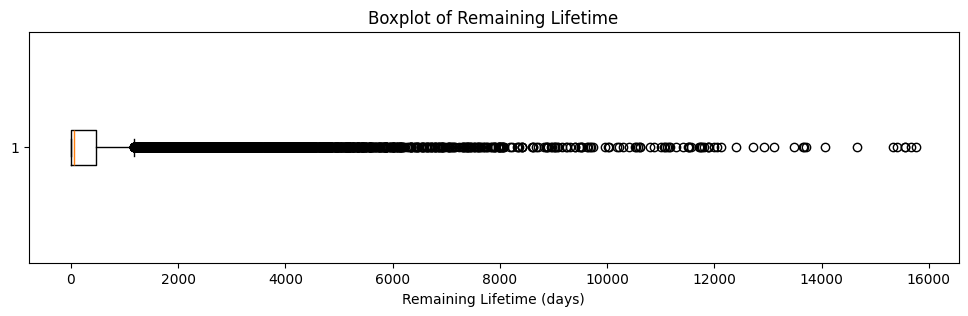

In [157]:
# create a boxplot of remaining lifetime
plt.style.use('default')
plt.figure(figsize=(12, 3))
plt.boxplot(balancing_df['REMAINING_LIFETIME'], vert=False)
plt.xlabel('Remaining Lifetime (days)')
plt.title('Boxplot of Remaining Lifetime')
plt.show()


In [158]:
balancing_df.shape

(24438, 79)

In [160]:
smogn_df = smogn.smoter(
    # main arguments
    data = balancing_df,
    y = 'REMAINING_LIFETIME',        
    k = 5,                    # specifies the number of neighbors to consider for interpolation used in over-sampling (default = 5)
    samp_method = 'extreme',  # string ('balance' or 'extreme', default = 'balance')

    # phi relevance arguments
    rel_thres = 0.8,         # threshold of rarity, positive real number (0 < R < 1), default = 0.50
    rel_method = 'auto',     # string ('auto' or 'manual')
    rel_xtrm_type = 'high',  # string ('low' or 'both' or 'high') -> high to oversample long lifetime objects
    rel_coef = 1.5           # positive real number (0 < R), specifies the box plot coefficient used to automatically determine extreme and therefore rare "minority" values in y, when rel_method = 'auto', default is 1.50
)

r_index: 100%|##########| 3004/3004 [00:09<00:00, 303.27it/s]


In [161]:
smogn_df.shape

(36289, 79)

In [162]:
smogn.box_plot_stats(balancing_df['REMAINING_LIFETIME'])['stats']

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_3064/1333034951.py:1: DeprecationWarning: the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  smogn.box_plot_stats(balancing_df['REMAINING_LIFETIME'])['stats']


array([   0.,    6.,   61.,  477., 1183.])

In [163]:
smogn.box_plot_stats(smogn_df['REMAINING_LIFETIME'])['stats']

/var/folders/xm/n65_n9sd78z4_zdw8r87klf00000gn/T/ipykernel_3064/2208976124.py:1: DeprecationWarning: the `interpolation=` argument to quantile was renamed to `method=`, which has additional options.
Users of the modes 'nearest', 'lower', 'higher', or 'midpoint' are encouraged to review the method they used. (Deprecated NumPy 1.22)
  smogn.box_plot_stats(smogn_df['REMAINING_LIFETIME'])['stats']


array([   0.,   45., 1032., 2187., 5400.])

<Axes: xlabel='REMAINING_LIFETIME', ylabel='Density'>

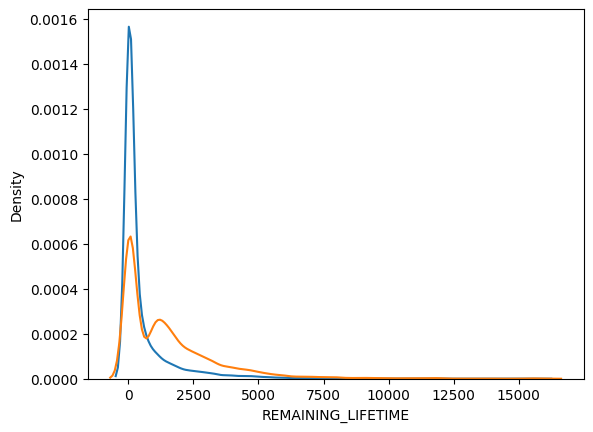

In [164]:
# plot remaining lifetime distribution 
sns.kdeplot(balancing_df['REMAINING_LIFETIME'], label = "Original")
sns.kdeplot(smogn_df['REMAINING_LIFETIME'], label = "Modified")

In [ ]:
# save to csv
smogn_df.to_csv("../Data/BalancedDataRaw.csv", index=False)

### Handling One Hot Encoded features with a winner takes it all strategy

In [35]:
import pandas as pd
smogn_df = pd.read_csv('../Data/BalancedDataRaw.csv')

In [36]:
one_hot_groups = {
    "OBJECT_TYPE": [col for col in smogn_df.columns if col.startswith("OBJECT_TYPE")],
    "COUNTRY": [col for col in smogn_df.columns if col.startswith("COUNTRY")],
    "SITE": [col for col in smogn_df.columns if col.startswith("SITE")]
}

In [37]:
def apply_argmax_to_group(df, columns):
    """
    Applies an argmax operation to the given group of one-hot columns.
    For each row, the index with the highest value is set to 1, 
    and all others are set to 0.
    """
    values = df[columns].values
    max_idx = np.argmax(values, axis=1) # Determine the index of the maximum value for each row
    binary_values = np.zeros_like(values) # Create an array of the same shape filled with zeros
    binary_values[np.arange(len(values)), max_idx] = 1 # Set the maximum value for each row to 1
    df.loc[:, columns] = binary_values # Update the DataFrame columns
    return df

# Apply the function for each defined group
for group, cols in one_hot_groups.items():
    if len(cols) > 0:
        smogn_df = apply_argmax_to_group(smogn_df, cols)

In [38]:
# split the data into training and test sets (80% training, 20% test)
train_smogn_df, test_smogn_df = train_test_split(smogn_df, test_size=0.2, random_state=42)

print("Training set size:", len(train_smogn_df))
print("Test set size:", len(test_smogn_df))

Training set size: 29031
Test set size: 7258


In [39]:
# save to csv
train_smogn_df.to_csv("../Data/TrainBalancedOHE.csv", index=False)
test_smogn_df.to_csv("../Data/TestBalancedOHE.csv", index=False)

In [40]:
# Track the new categorical columns as we create them
new_categorical_columns = []

for category_name, columns in one_hot_groups.items():
    # Get the column with the highest value (usually 1)
    smogn_df[category_name] = smogn_df[columns].idxmax(axis=1)
    # Strip the prefix to get the category value
    smogn_df[category_name] = smogn_df[category_name].str.replace(f"{category_name}_", "", regex=False)
    # Drop the original one-hot columns
    smogn_df = smogn_df.drop(columns=columns)
    # Track the new column
    new_categorical_columns.append(category_name)

# Reorder columns
smogn_df = smogn_df[new_categorical_columns + [col for col in smogn_df.columns if col not in new_categorical_columns]]


In [41]:
# split the data into training and test sets (80% training, 20% test)
train_smogn_df, test_smogn_df = train_test_split(smogn_df, test_size=0.2, random_state=42)

print("Training set size:", len(train_smogn_df))
print("Test set size:", len(test_smogn_df))

Training set size: 29031
Test set size: 7258


In [42]:
# save to csv
train_smogn_df.to_csv("../Data/TrainBalanced.csv", index=False)
test_smogn_df.to_csv("../Data/TestBalanced.csv", index=False)